# Assignment 3 — Does Quantization Make Code LLMs Brittle?

**NC State · CSC 591/791 · Trustworthy AI for Software Engineering · individual work**

Quantization papers report one headline number — usually pass@1 on clean, canonical
prompts — and call a 4-bit model "near-lossless" when that number barely moves. Real
prompts are not canonical: a function gets renamed, a docstring gets reworded, the
indentation changes. **When the clean score holds, does robustness hold too?**

In this assignment you will

1. **quantize** one code LLM yourself, four ways;
2. **evaluate** every version on the same robustness benchmarks, before and after quantization;
3. **analyse** whether quantization costs robustness that the clean score does not show.

There is **no answer key**. Nobody knows in advance whether 4-bit quantization hurts the
robustness of this model, so you are graded on whether your protocol is right, your
results are reproducible, and your claims match your evidence — not on reaching a
particular conclusion. A well-supported *"no significant change"* earns full credit.

### What is provided and what you write

The notebook provides the plumbing — data download, prompt construction, batched
generation with caching, sandboxed test execution, and the results/sample loggers. Cells
marked **`TODO`** are yours. Each TODO says what its function must return so that the
provided cells after it keep working.

| Part | What you do | Points |
|---|---|---|
| 1 | Load `fp16`, `int8`, `nf4`; run GPTQ yourself to produce `gptq4` | 20 |
| 2 | **E0** clean baseline, all four configurations | 10 |
| 3 | **E1** ReCode robustness, all four perturbation families | 25 |
| 4 | **E2** *or* **E3** (both → bonus) | 15 |
| 5 | Paired statistics and uncertainty | 10 |
| 6 | Report: the confound handled, flipped examples explained, claims matched to evidence | 15 |
| — | Submission: notebook with all outputs, run top to bottom; `README.md` explains your code | 5 |
| bonus | Both E2 and E3, or a fifth configuration (e.g. AWQ) | +5 |

### Rules

- Use a **GPU runtime**: *Runtime → Change runtime type → T4 GPU*.
- **Do not change** the model, the decoding settings, the prompt template (except inside E3),
  or the ReCode subset. They are fixed so that everyone's numbers are comparable.
- **Never use HumanEval or any ReCode file as GPTQ calibration data.** That leaks the test set
  into the quantized weights.
- AI assistance is allowed. Say in the report what you used it for; you remain responsible
  for every number.
- Submit two files to Gradescope: this notebook **with its outputs** (`.ipynb`) and a `README.md`
  explaining your code. Part 7 says what goes in each.

## Reading

| For | Paper |
|---|---|
| E1 | Wang et al., *ReCode: Robustness Evaluation of Code Generation Models*, ACL 2023 — [arXiv:2212.10264](https://arxiv.org/abs/2212.10264). Read §3 for the perturbation families and §4 for the metrics. |
| E1 (quantization) | Wei et al., *Greener yet Powerful: Taming Large Code Generation Models with Quantization* — [arXiv:2303.05378](https://arxiv.org/abs/2303.05378). They ran ReCode on quantized code models; compare your findings with theirs. |
| E2 | Fang et al., *EVALOOOP: A Self-Consistency-Centered Framework for Assessing Large Language Model Robustness in Programming* — [arXiv:2505.12185](https://arxiv.org/abs/2505.12185). |
| E3 | Sclar et al., *Quantifying Language Models' Sensitivity to Spurious Features in Prompt Design*, ICLR 2024 — [arXiv:2310.11324](https://arxiv.org/abs/2310.11324). |
| GPTQ | Frantar et al., *GPTQ*, ICLR 2023 — [arXiv:2210.17323](https://arxiv.org/abs/2210.17323). |
| int8 / NF4 | Dettmers et al., *LLM.int8()* — [arXiv:2208.07339](https://arxiv.org/abs/2208.07339); *QLoRA* (for NF4) — [arXiv:2305.14314](https://arxiv.org/abs/2305.14314). |

## 0. Setup

Run the install cell once. **If it changes the installed `torch`, restart the session
(*Runtime → Restart session*) and continue from the cell after it.** The next cell checks.

In [1]:
!pip install -q "llmcompressor==0.14.0" "transformers==5.17.0" "bitsandbytes>=0.46" scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.9/394.9 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 113.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.2/240.2 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.4 MB/s eta 0:00:00


In [4]:
import importlib.metadata as md
for pkg in ["torch", "transformers", "llmcompressor", "compressed-tensors", "bitsandbytes"]:
    print(f"{pkg:20s} {md.version(pkg)}")

import torch
assert torch.cuda.is_available(), "No GPU. Runtime -> Change runtime type -> T4 GPU."
print(torch.cuda.get_device_name(0))

torch                2.11.0+cu130
transformers         5.17.0
llmcompressor        0.14.0
compressed-tensors   0.19.0
bitsandbytes         0.50.2
Tesla T4


### Configuration

`QUICK = True` runs every evaluation on the first `N_QUICK` problems so you can debug the
whole notebook in minutes. **Set `QUICK = False` for the run you submit.**

Everything is written to the Colab VM's local disk (`/content/csc591-a3`). Generations are
cached there, so re-running a cell after an error resumes where it stopped. **The local disk
is wiped when the runtime is disconnected or deleted**, so keep the browser tab open during the
full run, and download the notebook as soon as it finishes.

In [5]:
import os

MODEL_ID = "Qwen/Qwen2.5-Coder-1.5B-Instruct"   # fixed for the whole class
DEVICE = "cuda"
DTYPE = "float16"            # T4 has no fast bfloat16
QUICK = False                # <- set to False for the graded run
N_QUICK = 20
MAX_NEW_TOKENS = 512
BATCH_SIZE = 16              # lower it if you run out of GPU memory
EXEC_TIMEOUT = 10            # seconds per test program

OUT_DIR = "/content/csc591-a3" if os.path.isdir("/content") else "./a3_out"

DATA_DIR = os.path.join(OUT_DIR, "data")
GEN_DIR = os.path.join(OUT_DIR, "generations")
FIG_DIR = os.path.join(OUT_DIR, "figures")
GPTQ_DIR = os.path.join(OUT_DIR, "gptq4-checkpoint")
for d in (DATA_DIR, GEN_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
print("outputs ->", OUT_DIR)

outputs -> /content/csc591-a3


In [6]:
import gc, json, sys, time, ast, re, random, hashlib, shutil, subprocess, tempfile, urllib.request
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, GenerationConfig

TORCH_DTYPE = getattr(torch, DTYPE)
random.seed(0); np.random.seed(0); torch.manual_seed(0)

## 1. Data: HumanEval and the ReCode perturbations

ReCode publishes its perturbed HumanEval files, so we download them rather than
regenerate them — everyone scores exactly the same prompts.

Two things about these files matter for your analysis:

- The **docstring** and **function-name** families perturb the ordinary HumanEval prompt.
  Their nominal (unperturbed) reference is `HumanEval.jsonl`.
- The **syntax** and **format** families perturb *partial code*: the prompt already
  contains the first half of the reference solution, and the model completes the rest.
  Their nominal reference is `humaneval_partial.jsonl`, **not** the ordinary prompt. Compare
  each perturbation with its own nominal set.

ReCode ships many transformations, several with up to 10 random seeds. To keep the compute
within a free T4, the class uses the fixed subset below: two transformations per family, seed 0.

In [7]:
RECODE_BASE = "https://raw.githubusercontent.com/amazon-science/recode/main/dataset-release"

NOMINAL_FILES = {
    "nominal":         "nominal/HumanEval.jsonl",
    "nominal_partial": "nominal/humaneval_partial.jsonl",
}

# family -> {variant name: file}. Fixed for the whole class; do not change.
RECODE_SUBSET = {
    "docstring": {
        "BackTranslation":     "nlaugmenter/humaneval_BackTranslation_s0.jsonl",
        "ButterFingers":       "nlaugmenter/humaneval_ButterFingersPerturbation_s0.jsonl",
    },
    "func_name": {
        "CamelCase":           "func_name/humaneval_FuncRenameCamelCase_s0.jsonl",
        "ButterFinger":        "func_name/humaneval_FuncRenameButterFinger_s0.jsonl",
    },
    "syntax": {
        "VarRenamerCB":        "natgen/humaneval_VarRenamerCB_s0.jsonl",
        "DeadCodeInserter":    "natgen/humaneval_DeadCodeInserter_s0.jsonl",
    },
    "format": {
        "TabIndent":           "format/humaneval_tab_indent_s0.jsonl",
        "Doc2Comments":        "format/humaneval_doc2comments_s0.jsonl",
    },
}
# which nominal set each family is compared against
FAMILY_NOMINAL = {"docstring": "nominal", "func_name": "nominal",
                  "syntax": "nominal_partial", "format": "nominal_partial"}


def fetch(rel_path):
    local = os.path.join(DATA_DIR, rel_path.replace("/", "__"))
    if not os.path.exists(local):
        if rel_path.startswith("nominal/"):
            url = f"{RECODE_BASE}/{rel_path}"
        else:
            url = f"{RECODE_BASE}/perturbed_finalized/humaneval/full/{rel_path}"
        urllib.request.urlretrieve(url, local)
    with open(local) as f:
        rows = [json.loads(line) for line in f]
    assert len(rows) == 164, (rel_path, len(rows))
    return rows


DATASETS = {name: fetch(path) for name, path in NOMINAL_FILES.items()}
for family, variants in RECODE_SUBSET.items():
    for variant, path in variants.items():
        DATASETS[f"{family}/{variant}"] = fetch(path)

TASK_IDS = [r["task_id"] for r in DATASETS["nominal"]]
if QUICK:
    TASK_IDS = TASK_IDS[:N_QUICK]
print(len(DATASETS), "datasets,", len(TASK_IDS), "problems per dataset")

10 datasets, 164 problems per dataset


Look at one perturbed problem next to its nominal version before you go on. Pick a few
`task_id`s and families and read the prompts. You will need this to explain flipped examples
in your report.

In [8]:
def show(dataset, task_id="HumanEval/0"):
    row = next(r for r in DATASETS[dataset] if r["task_id"] == task_id)
    print(f"--- {dataset}  entry_point={row['entry_point']}")
    print(row["prompt"])

show("nominal_partial")
show("syntax/VarRenamerCB")

--- nominal_partial  entry_point=has_close_elements
from typing import List


def has_close_elements(numbers: List[float], threshold: float) -> bool:
    """ Check if in given list of numbers, are any two numbers closer to each other than
    given threshold.
    >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
    False
    >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
    True
    """
    for idx, elem in enumerate(numbers):
        for idx2, elem2 in enumerate(numbers):
            if idx != idx2:
                distance = abs(elem - elem2)

--- syntax/VarRenamerCB  entry_point=has_close_elements
from typing import List


def has_close_elements(e: List[float], threshold: float) -> bool:
    """Check if in given list of numbers, are any two numbers closer to each other than
    given threshold.
    >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
    False
    >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
    True
    """
    for idx, elem in enumerate(e):
      

## 2. Prompting, generation, and test execution (provided)

**Prompt template (fixed).** The model sees the code in a user message, and its answer is
*prefilled* with that same code, so it continues the function exactly where the prompt
stops. This makes the instruct model behave like a completion model, which is what ReCode's
partial-code perturbations assume. Generation stops at the closing code fence.

**Decoding (fixed).** Greedy, `max_new_tokens=512`, no repetition penalty. `generate()`
fills any setting we leave unset from the model's own `generation_config`, which for Qwen
includes sampling settings and `repetition_penalty=1.1`, so every one of them is set
explicitly. The only thing that differs between your runs is the weights.

**Execution.** `prompt + completion` is first *sanitized*: only imports, function and class
definitions, and plain assignments are kept, so a self-test the model appended (often with
wrong expected values) cannot fail the program before the real tests run. The HumanEval tests
and `check(entry_point)` are then appended, and the program runs in a separate Python process
with a timeout. `SAMPLES` keeps the raw completion. Generated code is untrusted; it runs inside your
Colab VM, which is disposable.

In [9]:
INSTRUCTION = "Complete the following Python function. Keep the function name and signature unchanged."
FENCE = "`" * 3
CHAT_STOP = [FENCE]


def chat_input(tok, prompt, instruction=INSTRUCTION):
    """Chat-formatted input whose assistant turn is prefilled with the code prompt."""
    body = prompt if prompt.endswith("\n") else prompt + "\n"
    user = f"{instruction}\n\n{FENCE}python\n{body}{FENCE}"
    text = tok.apply_chat_template([{"role": "user", "content": user}],
                                   tokenize=False, add_generation_prompt=True)
    return text + f"{FENCE}python\n" + prompt


def truncate_at_stop(text, stop):
    cut = min([i for s in stop for i in [text.find(s)] if i >= 0], default=len(text))
    return text[:cut]


GEN_STATS = defaultdict(lambda: {"tokens": 0, "seconds": 0.0})


@torch.inference_mode()
def generate(model, tok, inputs, stop, max_new_tokens=MAX_NEW_TOKENS, batch_size=BATCH_SIZE, stats_key=None):
    """Greedy batched generation. Returns one completion string per input, cut at the first stop string."""
    # generate() fills every field left unset here from the model's own generation_config, which
    # for Qwen includes repetition_penalty=1.1 and sampling settings. Set them all explicitly.
    gen_config = GenerationConfig(
        max_new_tokens=max_new_tokens, do_sample=False, stop_strings=stop or None,
        repetition_penalty=1.0, temperature=1.0, top_p=1.0, top_k=50,
        pad_token_id=tok.pad_token_id, eos_token_id=model.generation_config.eos_token_id)
    order = sorted(range(len(inputs)), key=lambda i: len(inputs[i]), reverse=True)
    outputs = [None] * len(inputs)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        enc = tok([inputs[i] for i in idx], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        t0 = time.time()
        out = model.generate(**enc, generation_config=gen_config, tokenizer=tok)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        new = out[:, enc["input_ids"].shape[1]:]
        if stats_key:
            GEN_STATS[stats_key]["seconds"] += time.time() - t0
            GEN_STATS[stats_key]["tokens"] += int((new != tok.pad_token_id).sum())
        for i, text in zip(idx, tok.batch_decode(new, skip_special_tokens=True)):
            outputs[i] = truncate_at_stop(text, stop) if stop else text
    return outputs

In [10]:
class GenCache:
    """Append-only cache of generations, one JSONL file per configuration.

    Entries are keyed by a hash of the exact model input and generation settings, so a changed
    prompt is regenerated and an identical one (e.g. E0 and E2 loop 1) is generated only once.
    """

    def __init__(self, config_id):
        self.path = os.path.join(GEN_DIR, f"{config_id}.jsonl")
        self.data = {}
        if os.path.exists(self.path):
            with open(self.path) as f:
                for line in f:
                    rec = json.loads(line)
                    self.data[rec["key"]] = rec["output"]

    DECODING = "greedy-rp1.0"   # part of the key: change it if you change the decoding settings

    @classmethod
    def key(cls, text, stop, max_new_tokens):
        return hashlib.sha1(json.dumps([text, stop, max_new_tokens, cls.DECODING]).encode()).hexdigest()

    def run(self, model, tok, inputs, stop, stats_key=None, chunk=64, max_new_tokens=MAX_NEW_TOKENS):
        keys = [self.key(x, stop, max_new_tokens) for x in inputs]
        todo = [(k, x) for k, x in dict(zip(keys, inputs)).items() if k not in self.data]
        for start in range(0, len(todo), chunk):
            part = todo[start:start + chunk]
            outs = generate(model, tok, [x for _, x in part], stop, stats_key=stats_key,
                            max_new_tokens=max_new_tokens)
            with open(self.path, "a") as f:
                for (k, _), o in zip(part, outs):
                    self.data[k] = o
                    f.write(json.dumps({"key": k, "output": o}) + "\n")
            print(f"  generated {min(start + chunk, len(todo))}/{len(todo)}", end="\r")
        return [self.data[k] for k in keys]

In [11]:
def sanitize(code):
    """Keep imports, definitions and call-free assignments; drop top-level code the model added
    (its own asserts, prints, `if __name__ == "__main__":` blocks). Unparsable code is returned
    unchanged and fails at execution."""
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return code
    defs = (ast.Import, ast.ImportFrom, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)
    tree.body = [n for n in tree.body if isinstance(n, defs) or
                 (isinstance(n, (ast.Assign, ast.AnnAssign))
                  and not any(isinstance(c, ast.Call) for c in ast.walk(n)))]
    return ast.unparse(tree)


def build_program(prompt, completion, row):
    return f"{sanitize(prompt + completion)}\n\n{row['test']}\n\ncheck({row['entry_point']})\n"


def run_program(program, timeout=EXEC_TIMEOUT):
    """Run a program in a fresh interpreter. Returns (passed, status)."""
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "prog.py")
        with open(path, "w") as f:
            f.write(program)
        try:
            r = subprocess.run([sys.executable, path], cwd=tmp, capture_output=True,
                               text=True, timeout=timeout)
        except subprocess.TimeoutExpired:
            return False, "timeout"
    if r.returncode == 0:
        return True, "passed"
    err = r.stderr.strip().splitlines()
    return False, (err[-1][:200] if err else f"exit {r.returncode}")


def run_programs(programs, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(run_program, programs))


# sanity check: the reference solutions must pass
_rows = [r for r in DATASETS["nominal"] if r["task_id"] in TASK_IDS]
_res = run_programs([build_program(r["prompt"], r["canonical_solution"], r) for r in _rows])
print("reference solutions passing:", sum(p for p, _ in _res), "/", len(_rows))

reference solutions passing: 164 / 164


In [12]:
SAMPLES = []      # one dict per generation (prompt, raw output, verdict)
RESULTS = []      # one dict per metric
CONFIG_META = {
    "fp16":  {"method": "none",               "bits": 16},
    "int8":  {"method": "bnb-llm.int8",       "bits": 8},
    "nf4":   {"method": "bnb-nf4",            "bits": 4},
    "gptq4": {"method": "gptq-w4a16-g128",    "bits": 4},
}


def record_result(config, eval_id, variant, metric, n, value, ci_low=None, ci_high=None):
    meta = CONFIG_META[config]
    RESULTS.append({"config": config, "method": meta["method"], "bits": meta["bits"],
                    "eval": eval_id, "variant": variant, "metric": metric, "n": n,
                    "value": value, "ci_low": ci_low, "ci_high": ci_high})


def evaluate_dataset(config, model, tok, cache, dataset, eval_id, instruction=INSTRUCTION, variant=None):
    """Generate and test every problem of one dataset. Returns {task_id: passed}."""
    rows = [r for r in DATASETS[dataset] if r["task_id"] in TASK_IDS]
    variant = variant or dataset
    inputs = [chat_input(tok, r["prompt"], instruction) for r in rows]
    outs = cache.run(model, tok, inputs, CHAT_STOP, stats_key=config)
    verdicts = run_programs([build_program(r["prompt"], o, r) for r, o in zip(rows, outs)])
    passed = {}
    for r, o, (ok, status) in zip(rows, outs, verdicts):
        passed[r["task_id"]] = ok
        SAMPLES.append({"config": config, "eval": eval_id, "variant": variant, "item_id": r["task_id"],
                        "prompt": r["prompt"], "output": o, "passed": ok, "status": status})
    return passed

## 3. Part 1 — Quantize the model (20 pts)

| ID | Precision | Method | Calibration data |
|---|---|---|---|
| `fp16` | 16-bit | none — the baseline | — |
| `int8` | 8-bit | LLM.int8() via `bitsandbytes` | none |
| `nf4` | 4-bit | NF4 via `bitsandbytes` | none |
| `gptq4` | 4-bit weights, 16-bit activations | GPTQ, group size 128, via `llmcompressor` | **you choose** |

`int8` and `nf4` quantize at load time. `gptq4` is the one where you actually run a
quantization algorithm: choose a calibration set, run GPTQ, save the checkpoint, and reload it.

### TODO 1a — `load_model`

In [13]:
def load_tokenizer():
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    tok.padding_side = "left"          # required for batched generation with a decoder-only model
    return tok


def load_gptq4():
    """Load the GPTQ checkpoint saved in TODO 1b as an fp16 model whose Linear weights are the
    dequantized 4-bit values.

    Why not just `from_pretrained(GPTQ_DIR)`? With transformers 5.17.0 + compressed-tensors 0.19.0 on
    Colab that call did not build the packed-weight layout: the 196 quantized Linear layers were
    reported MISSING (random init) and `weight_packed`/`weight_scale` UNEXPECTED, so the model produced
    garbage (0/20 on HumanEval). This does by hand what compressed-tensors does on the first forward
    pass: unpack the int4 weights from the checkpoint and multiply by the per-group scales.
    Everything not quantized (embeddings, norms, biases, lm_head) is taken from the original model:
    GPTQ leaves those untouched.
    """
    from safetensors import safe_open
    from compressed_tensors.compressors.pack_quantized.helpers import unpack_from_int32

    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=TORCH_DTYPE, device_map=DEVICE)
    cfg = json.load(open(os.path.join(GPTQ_DIR, "config.json")))["quantization_config"]
    w = cfg["config_groups"]["group_0"]["weights"]
    assert (w["num_bits"], w["group_size"], w["symmetric"], w["strategy"]) == (4, 128, True, "group"), w
    group = w["group_size"]

    rel_errs, n_done = [], 0
    with safe_open(os.path.join(GPTQ_DIR, "model.safetensors"), framework="pt", device="cpu") as f:
        keys = set(f.keys())
        assert not any(k.endswith(("weight_g_idx", "weight_zero_point")) for k in keys), \
            "checkpoint has g_idx / zero points: this loader assumes plain symmetric group quantization"
        for name, mod in model.named_modules():
            if not isinstance(mod, torch.nn.Linear) or name == "lm_head":
                continue
            packed = f.get_tensor(f"{name}.weight_packed").to(DEVICE)
            scale = f.get_tensor(f"{name}.weight_scale").to(DEVICE).float()
            shape = torch.Size([int(s) for s in f.get_tensor(f"{name}.weight_shape")])
            w_int = unpack_from_int32(packed, 4, shape)
            deq = w_int.float() * scale.repeat_interleave(group, dim=1)[:, :shape[1]]
            ref = mod.weight.data.float()
            rel_errs.append(float((deq - ref).norm() / ref.norm()))
            mod.weight.data.copy_(deq.to(mod.weight.dtype))
            n_done += 1
        assert n_done == sum(k.endswith(".weight_packed") for k in keys), "unconsumed packed weights"

    # A correct 4-bit group-128 dequantization sits within ~10-20% of the original weights per layer.
    # A wrong bit layout or scale axis gives >100%.
    print(f"gptq4: dequantized {n_done} layers, relative weight error vs fp16: "
          f"mean {np.mean(rel_errs):.3f}, max {np.max(rel_errs):.3f}")
    assert np.max(rel_errs) < 0.5 and n_done == 196, "GPTQ checkpoint did not dequantize correctly"
    return model.eval()


def load_model(config):
    """Return the model for `config` in eval mode on the GPU.

    fp16  : the original weights in float16
    int8  : LLM.int8() through BitsAndBytesConfig
    nf4   : 4-bit NF4 through BitsAndBytesConfig, computing in float16
    gptq4 : the checkpoint you saved to GPTQ_DIR in TODO 1b
    """
    if config == "gptq4":
        return load_gptq4()
    quant = None
    if config == "fp16":
        pass
    elif config == "int8":
        quant = BitsAndBytesConfig(load_in_8bit=True)
    elif config == "nf4":
        quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                   bnb_4bit_compute_dtype=TORCH_DTYPE)
    else:
        raise ValueError(f"unknown config {config!r}")
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=TORCH_DTYPE, device_map=DEVICE,
                                                 quantization_config=quant)
    return model.eval()

### TODO 1b — run GPTQ

Use `llmcompressor`'s `oneshot` with a `GPTQModifier` whose scheme is `"W4A16"` (4-bit
symmetric integer weights, group size 128, 16-bit activations). Leave `lm_head` unquantized.
Save with `save_compressed=True`, and save the tokenizer next to it.

**Calibration data is your design decision; justify it in the report.** GPTQ chooses each
layer's rounding to minimise the error on the calibration activations, so what you
calibrate on may matter. Some options: code instructions (e.g.
`theblackcat102/evol-codealpaca-v1`), general text (e.g. `wikitext`), or chat data. Record
the dataset, number of samples and sequence length. **HumanEval and ReCode are forbidden.**

**Load the model in float32 for calibration**, not float16. In float16 the T4 run overflows
inside the network, the Hessians become invalid, and llmcompressor quietly quantizes almost
every layer with plain round-to-nearest instead of GPTQ — you would be comparing NF4 against
RTN without knowing it. The cell below checks for this and refuses to keep such a checkpoint.
(Evaluation still loads the saved checkpoint in float16.)

On a T4, 256 samples of 512 tokens takes a few minutes. The cell skips itself if a
checkpoint already exists.

In [14]:
from llmcompressor import oneshot
from llmcompressor.modifiers.quantization import GPTQModifier
from datasets import load_dataset

# Code instructions with solutions: matches the domain of the evaluation (Python code
# completion) and the model's chat format, and is a different source from HumanEval/ReCode.
CALIB_DATASET = "theblackcat102/evol-codealpaca-v1"
NUM_CALIB_SAMPLES = 256
CALIB_SEQ_LEN = 512
CALIB_SEED = 42


def build_calibration_set(tok):
    """Return a datasets.Dataset with tokenized `input_ids` and `attention_mask` columns."""
    ds = load_dataset(CALIB_DATASET, split="train").shuffle(seed=CALIB_SEED)

    # Decontamination: HumanEval is forbidden, so skip any sample that defines a HumanEval function.
    markers = [f"def {r['entry_point']}(" for r in DATASETS["nominal"]]
    def clean(ex):
        text = ex["instruction"] + ex["output"]
        return not any(m in text for m in markers)
    n_before = min(len(ds), 4 * NUM_CALIB_SAMPLES)
    ds = ds.select(range(n_before)).filter(clean)
    print(f"calibration: dropped {n_before - len(ds)} of {n_before} candidates for defining a HumanEval function")
    ds = ds.select(range(NUM_CALIB_SAMPLES))

    def tokenize(ex):
        text = tok.apply_chat_template(
            [{"role": "user", "content": ex["instruction"]},
             {"role": "assistant", "content": ex["output"]}], tokenize=False)
        return tok(text, max_length=CALIB_SEQ_LEN, truncation=True, padding=False,
                   add_special_tokens=False)
    ds = ds.map(tokenize, remove_columns=ds.column_names)
    return ds


def run_gptq():
    tok = load_tokenizer()
    # float32 for calibration: in float16 the Hessians overflow and GPTQ silently becomes RTN
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32, device_map=DEVICE)
    ds = build_calibration_set(tok)
    recipe = GPTQModifier(targets="Linear", scheme="W4A16", ignore=["lm_head"])
    oneshot(model=model, dataset=ds, recipe=recipe,
            max_seq_length=CALIB_SEQ_LEN, num_calibration_samples=NUM_CALIB_SAMPLES)
    model.save_pretrained(GPTQ_DIR, save_compressed=True)
    tok.save_pretrained(GPTQ_DIR)
    del model
    gc.collect()
    torch.cuda.empty_cache()


from loguru import logger as _llmc_logger


def run_gptq_checked(max_fallback=0.10):
    """Run GPTQ and fail if too many layers silently fell back to round-to-nearest."""
    warnings_seen = []
    sink = _llmc_logger.add(lambda m: warnings_seen.append(m.record["message"]), level="WARNING")
    try:
        run_gptq()
    finally:
        _llmc_logger.remove(sink)
    for msg in warnings_seen:
        m = re.search(r"Hessian inversion failed for (\d+)/(\d+) modules", msg)
        if m and int(m.group(1)) / int(m.group(2)) > max_fallback:
            shutil.rmtree(GPTQ_DIR, ignore_errors=True)
            raise RuntimeError(
                f"GPTQ fell back to round-to-nearest for {m.group(1)}/{m.group(2)} layers, so this "
                "checkpoint is not a GPTQ model. It was deleted. Check the calibration dtype and data.")
    print("GPTQ fallback check passed")


if not os.path.exists(os.path.join(GPTQ_DIR, "config.json")):
    t0 = time.time()
    run_gptq_checked()
    print(f"GPTQ done in {time.time() - t0:.0f}s")
else:
    print("using existing checkpoint at", GPTQ_DIR)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3426: UserWarning: Attempting to save a model with offloaded modules. Ensure that unallocated cpu memory exceeds the `shard_size` (50GB default)
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-15T01:44:48.2901 | resave_config | INFO - Resaved original config with patched fields to /content/csc591-a3/gptq4-checkpoint/config.json


Dispatching model: 100%|██████████| 371/371 [00:00<00:00, 15056.91it/s]


GPTQ fallback check passed
GPTQ done in 579s


### Efficiency (provided)

Record what each configuration buys you. Note one subtlety for your report: `transformers`
stores the GPTQ checkpoint compressed on disk, but on a T4 it **decompresses the weights to
fp16 on the first forward pass**. Its numbers are the numbers of 4-bit weights, but its GPU
memory and speed are not what a dedicated int4 kernel (e.g. vLLM) would give.

In [15]:
def dir_size_gb(path):
    return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs) / 1e9


def efficiency_row(config, model):
    row = {"config": config, "weights_in_memory_gb": model.get_memory_footprint() / 1e9}
    if config == "gptq4":
        row["checkpoint_on_disk_gb"] = dir_size_gb(GPTQ_DIR)
    if torch.cuda.is_available():
        row["peak_gpu_memory_gb"] = torch.cuda.max_memory_allocated() / 1e9
    s = GEN_STATS[config]
    row["tokens_per_second"] = s["tokens"] / s["seconds"] if s["seconds"] else None
    return row


EFFICIENCY = []

### Sanity check before the long runs

Load one configuration and look at its output on two problems. If the completion is empty
or garbled, fix that before you spend GPU time.

In [16]:
tok = load_tokenizer()
_model = load_model("fp16")
_rows = [r for r in DATASETS["nominal"]][:2]
for r, o in zip(_rows, generate(_model, tok, [chat_input(tok, r["prompt"]) for r in _rows], CHAT_STOP)):
    print("=" * 60, r["task_id"]); print(r["prompt"] + o)
del _model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

============================================================ HumanEval/0
from typing import List


def has_close_elements(numbers: List[float], threshold: float) -> bool:
    """ Check if in given list of numbers, are any two numbers closer to each other than
    given threshold.
    >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
    False
    >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
    True
    """
    numbers.sort()  # Sort the list to make it easier to check for close elements
    for i in range(len(numbers) - 1):
        if abs(numbers[i] - numbers[i + 1]) < threshold:
            return True
    return False

============================================================ HumanEval/1
from typing import List


def separate_paren_groups(paren_string: str) -> List[str]:
    """ Input to this function is a string containing multiple groups of nested parentheses. Your goal is to
    separate those group into separate strings and return the list of those.
    Separate gro

## 4. Parts 2–4 — Run the evaluations

The loop below loads one configuration at a time, runs **E0** and **E1** on it, and runs
**E2** and/or **E3** if you set the flags. Everything is cached, so if the session dies,
re-run the setup cells and this cell; finished generations are not regenerated.

**Time budget (measured on a free Colab T4, `QUICK = False`):** the GPTQ step takes about
10 minutes, and E0 + E1 + E2 over all four configurations about **2.5 hours**. E3 adds
roughly another hour (estimate). `int8` (LLM.int8()) generates about 3× slower than the
others and dominates the total. Do the `QUICK` run first, then start the full run early —
on a free runtime that may mean a separate session.

The `TODO` functions this loop calls are defined in the cells after it — run those
cells first, then come back to this one. E0 and E1 need nothing from you to *run*; your
E1 work is the metric computation in Part 3.

In [17]:
CONFIGS = ["fp16", "int8", "nf4", "gptq4"]
RUN_E2 = True     # EVALOOOP self-consistency loop  (do at least one of E2/E3)
RUN_E3 = False    # prompt-template sensitivity
E2_MAX_LOOPS = 3

PASS = defaultdict(dict)      # PASS[config][dataset or variant] = {task_id: passed}
E2_OUT = {}                   # E2_OUT[config] = output of run_evaloop

In [18]:
def run_all():
    tok = load_tokenizer()
    for config in CONFIGS:
        print(f"===== {config}")
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        model = load_model(config)
        cache = GenCache(config)

        # E0: both nominal sets (the partial one is the reference for syntax/format)
        for ds in NOMINAL_FILES:
            PASS[config][ds] = evaluate_dataset(config, model, tok, cache, ds, "E0")
        # E1: ReCode subset
        for family, variants in RECODE_SUBSET.items():
            for variant in variants:
                name = f"{family}/{variant}"
                PASS[config][name] = evaluate_dataset(config, model, tok, cache, name, "E1")
        if RUN_E2:
            E2_OUT[config] = run_evaloop(config, model, tok, cache, E2_MAX_LOOPS)
        if RUN_E3:
            for tid, instruction in E3_TEMPLATES.items():
                PASS[config][f"E3/{tid}"] = run_template(config, model, tok, cache, tid, instruction)

        EFFICIENCY.append(efficiency_row(config, model))
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 5. Part 2 — E0 clean baseline (10 pts)

pass@1 with greedy decoding is just the fraction of problems whose single completion passes.
Report it for both nominal sets, with a 95% confidence interval (TODO 5 provides the
bootstrap you need). The helper below writes the rows.

In [19]:
def pass_at_1(passed):
    return float(np.mean(list(passed.values())))


def record_e0():
    for config in CONFIGS:
        for ds in NOMINAL_FILES:
            p = PASS[config][ds]
            lo, hi = bootstrap_ci(list(p.values()))
            record_result(config, "E0", ds, "pass@1", len(p), pass_at_1(p), lo, hi)

## 6. Part 3 — E1 ReCode robustness metrics (25 pts)

### TODO 3 — `recode_metrics`

Implement the three ReCode metrics for one perturbation, comparing it with **its own nominal
set** (`FAMILY_NOMINAL`). With greedy decoding and one seed per transformation, ReCode §4
reduces to the following:

- **Robust Pass@1** — fraction of problems solved on the perturbed prompt.
- **Robust Drop@1** — `(nominal pass@1 − robust pass@1) / nominal pass@1`.
- **Robust Relative@1** — fraction of problems whose outcome *changes* in either direction
  (pass→fail or fail→pass).

Also return the **conditional robustness** this assignment requires: among problems the
configuration solves on the nominal prompt, the fraction it still solves under the
perturbation. Section 8 explains why you need it.

Then implement `family_worst_case`: a problem counts as robust for a family only if it
passes **every** transformation in that family. This is the per-family view.

In [20]:
def recode_metrics(nominal, perturbed):
    """nominal, perturbed: {task_id: bool} over the same task_ids.

    Return a dict with keys: robust_pass, robust_drop, robust_relative, conditional_robust, n.
    """
    assert set(nominal) == set(perturbed), "nominal and perturbed must cover the same problems"
    ids = sorted(nominal)
    nom = np.array([nominal[t] for t in ids], dtype=bool)
    per = np.array([perturbed[t] for t in ids], dtype=bool)
    nom_pass, rob_pass = nom.mean(), per.mean()
    return {
        "robust_pass": float(rob_pass),
        # relative drop in pass@1; undefined if the nominal prompt solves nothing
        "robust_drop": float((nom_pass - rob_pass) / nom_pass) if nom_pass > 0 else float("nan"),
        # outcome changed in either direction
        "robust_relative": float((nom != per).mean()),
        # among problems solved on the nominal prompt, the share still solved when perturbed
        "conditional_robust": float(per[nom].mean()) if nom.any() else float("nan"),
        "n": len(ids),
    }


def family_worst_case(config, family):
    """Return {task_id: bool}: True iff the problem passes every variant of `family`."""
    per_variant = [PASS[config][f"{family}/{variant}"] for variant in RECODE_SUBSET[family]]
    return {t: all(p[t] for p in per_variant) for t in per_variant[0]}

In [21]:
def record_e1():
    for config in CONFIGS:
        for family, variants in RECODE_SUBSET.items():
            nominal = PASS[config][FAMILY_NOMINAL[family]]
            for variant in list(variants) + ["worst_case"]:
                perturbed = (family_worst_case(config, family) if variant == "worst_case"
                             else PASS[config][f"{family}/{variant}"])
                m = recode_metrics(nominal, perturbed)
                for metric in ("robust_pass", "robust_drop", "robust_relative", "conditional_robust"):
                    record_result(config, "E1", f"{family}/{variant}", metric, m["n"], m[metric])

## 7. Part 4 — E2 *or* E3 (15 pts; both for the bonus)

### E2 — EVALOOOP self-consistency loop

EVALOOOP perturbs the model with its **own** output: code → natural-language description →
code → … until the code stops passing its tests. Robustness is the **Average Sustainable
Loops (ASL)**: the mean number of consecutive loops a problem survives. Read the paper for
the exact definition and reproduce it; document any difference.

Our adaptation, which you may refine but must document: the paper uses MBPP+ and ten
loops; we use the HumanEval problems already loaded, and `E2_MAX_LOOPS` = 3 loops.

Why only three: with greedy decoding the loop reaches a **fixed point** quickly. Once the
model writes the same code twice, it describes it the same way and regenerates the same code,
so a problem that survives loop 3 survives every later loop. In our pilot, loops 3, 4 and 5
gave identical pass rates for every configuration. Discuss in your report what this means
for ASL as a robustness measure under greedy decoding.

Helpers are provided. `strip_docstring` matters: if the model is shown the previous
docstring, it can copy it instead of describing the code, and the loop measures nothing.

In [22]:
DESCRIBE_INSTRUCTION = (
    "Here is a Python function without its docstring. Write the docstring: say what the "
    "function does, what each parameter means, and what it returns, and give one or two "
    "examples in doctest format (>>> call, then the expected result).")
DOC_STOP = ['"""', FENCE]


def strip_docstring(code, entry_point):
    """Remove the docstring of `entry_point`. Returns None if the code does not parse."""
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return None
    for node in ast.walk(tree):
        if isinstance(node, ast.FunctionDef) and node.name == entry_point:
            body = node.body
            if body and isinstance(body[0], ast.Expr) and isinstance(getattr(body[0], "value", None), ast.Constant) \
                    and isinstance(body[0].value.value, str):
                node.body = body[1:] or [ast.Pass()]
    return ast.unparse(tree)


def signature_header(original_prompt, entry_point):
    """The original prompt up to and including the signature of `entry_point` (imports and
    helper functions included), and the indentation of the function body."""
    lines = original_prompt.splitlines(keepends=True)
    start = next(i for i, l in enumerate(lines) if l.lstrip().startswith(f"def {entry_point}("))
    end = start
    while not lines[end].rstrip().endswith(":"):
        end += 1
    indent = " " * (len(lines[start]) - len(lines[start].lstrip()) + 4)
    return "".join(lines[:end + 1]), indent


def describe_input(tok, code, original_prompt, entry_point):
    """Ask for a docstring. The answer is prefilled up to the opening quotes, so the model can
    only write docstring text; generation stops at the closing quotes (DOC_STOP)."""
    header, indent = signature_header(original_prompt, entry_point)
    user = f"{DESCRIBE_INSTRUCTION}\n\n{FENCE}python\n{code}\n{FENCE}"
    text = tok.apply_chat_template([{"role": "user", "content": user}], tokenize=False, add_generation_prompt=True)
    return text + f'{FENCE}python\n{header}{indent}"""\n'


def prompt_from_description(original_prompt, entry_point, description):
    """The original header and signature, with the generated description as the docstring."""
    header, indent = signature_header(original_prompt, entry_point)
    lines = [l.strip() for l in description.strip("\n").splitlines()]
    doc = "\n".join(indent + l if l else "" for l in lines)
    return f'{header}{indent}"""\n{doc}\n{indent}"""\n'

### TODO 4a — `run_evaloop`

Loop 1 is the ordinary E0 generation from the original prompt. For each later loop, take the
previous loop's code (prompt + completion) for the problems that are still passing, strip its
docstring, ask the model to describe it (`describe_input`, stop strings `DOC_STOP`, 256 new
tokens), build a new prompt with `prompt_from_description`, generate code from it with
`chat_input`, and test it against the original tests. Use `cache.run` for every generation
so the work is cached. Append a `SAMPLES` row for
each generated program, with `eval="E2"` and `variant=f"loop{k}"`.

In [23]:
def run_evaloop(config, model, tok, cache, max_loops):
    """Return {"survived": {task_id: int}, "pass_by_loop": [pass@1 at loop 1, ..., loop max_loops]}.

    survived[t] = number of consecutive loops, starting at loop 1, that problem t passes (0..max_loops).
    pass_by_loop[k-1] = fraction of all problems still passing at loop k.
    """
    rows = {r["task_id"]: r for r in DATASETS["nominal"] if r["task_id"] in TASK_IDS}
    survived = {t: 0 for t in rows}
    alive = list(rows)                 # problems that passed every loop so far
    code = {}                          # code that passed in the previous loop
    pass_by_loop = []

    for k in range(1, max_loops + 1):
        if k == 1:
            # loop 1 is the ordinary E0 generation from the original prompt
            prompts = {t: rows[t]["prompt"] for t in alive}
        else:
            # previous code -> docstring-free code -> model-written description -> new prompt
            stripped = {t: strip_docstring(code[t], rows[t]["entry_point"]) for t in alive}
            alive = [t for t in alive if stripped[t] is not None]
            d_inputs = [describe_input(tok, stripped[t], rows[t]["prompt"], rows[t]["entry_point"])
                        for t in alive]
            descs = cache.run(model, tok, d_inputs, DOC_STOP, stats_key=config, max_new_tokens=256)
            prompts = {t: prompt_from_description(rows[t]["prompt"], rows[t]["entry_point"], d)
                       for t, d in zip(alive, descs)}

        inputs = [chat_input(tok, prompts[t]) for t in alive]
        outs = cache.run(model, tok, inputs, CHAT_STOP, stats_key=config)
        # always tested against the ORIGINAL problem's tests
        verdicts = run_programs([build_program(prompts[t], o, rows[t]) for t, o in zip(alive, outs)])

        still_alive = []
        for t, o, (ok, status) in zip(alive, outs, verdicts):
            SAMPLES.append({"config": config, "eval": "E2", "variant": f"loop{k}", "item_id": t,
                            "prompt": prompts[t], "output": o, "passed": ok, "status": status})
            if ok:
                survived[t] += 1
                # the code the next loop describes is what was actually tested (sanitized)
                code[t] = sanitize(prompts[t] + o)
                still_alive.append(t)
        alive = still_alive
        pass_by_loop.append(len(alive) / len(rows))
        print(f"  [{config}] loop {k}: {len(alive)}/{len(rows)} still passing")

    return {"survived": survived, "pass_by_loop": pass_by_loop}


def asl(survived):
    """Average Sustainable Loops: mean number of consecutive loops survived per problem."""
    return float(np.mean(list(survived.values())))

### E3 — prompt-template sensitivity

Every template below asks for the same thing; only the wording and layout of the user
message change. (The assistant prefill is the same in all of them, so the model continues
the same code.) `T0` is the template E0 used, so its result is reused.

In [24]:
E3_TEMPLATES = {
    "T0": INSTRUCTION,
    "T1": "Finish this function.",
    "T2": ("You are an expert Python programmer. Read the docstring carefully and implement the "
           "function so that it passes all hidden unit tests. Do not rename the function."),
    "T3": "### Task\nImplement the function below in Python.\n### Constraints\nKeep the signature.",
    "T4": "complete the python function:",
    "T5": "Please write the body of the function that follows, keeping its name and parameters as they are.",
}


def run_template(config, model, tok, cache, tid, instruction):
    if tid == "T0":
        return PASS[config]["nominal"]
    return evaluate_dataset(config, model, tok, cache, "nominal", "E3", instruction=instruction, variant=tid)

### TODO 4b — E3 spread

For each configuration, compute pass@1 under every template, and the **spread** (max − min
across templates), following Sclar et al.'s notion of format sensitivity. Also count, per
configuration, how many problems are *template-sensitive*: solved under some templates and
failed under others. Write the rows with `record_result(config, "E3", ...)`.

In [25]:
def record_e3():
    """pass@1 per template, spread (max - min across templates) and template-sensitive problems."""
    for config in CONFIGS:
        per_t = {tid: PASS[config][f"E3/{tid}"] for tid in E3_TEMPLATES}
        ids = sorted(next(iter(per_t.values())))
        n = len(ids)
        M = np.array([[p[t] for t in ids] for p in per_t.values()], dtype=float)   # templates x problems

        for tid, p in per_t.items():
            lo, hi = bootstrap_ci(list(p.values()))
            record_result(config, "E3", tid, "pass@1", n, pass_at_1(p), lo, hi)

        # spread of the template pass rates, with a bootstrap CI over problems. max - min of noisy
        # estimates is biased upward, so read it together with its CI and the per-template CIs.
        rates = M.mean(axis=1)
        idx = np.random.default_rng(0).integers(0, n, size=(10_000, n))
        boot = M[:, idx].mean(axis=2)                                             # templates x resamples
        lo, hi = np.percentile(boot.max(axis=0) - boot.min(axis=0), [2.5, 97.5])
        record_result(config, "E3", "all", "spread", n, float(rates.max() - rates.min()), float(lo), float(hi))

        # problems solved under some templates and failed under others
        wins = M.sum(axis=0)
        sensitive = int(((wins > 0) & (wins < len(per_t))).sum())
        record_result(config, "E3", "all", "template_sensitive_problems", n, sensitive)
        record_result(config, "E3", "all", "template_sensitive_frac", n, sensitive / n)

In [26]:
def record_e2():
    for config, out in E2_OUT.items():
        n = len(out["survived"])
        lo, hi = bootstrap_ci(list(out["survived"].values()))
        record_result(config, "E2", "all", "ASL", n, asl(out["survived"]), lo, hi)
        for k, p in enumerate(out["pass_by_loop"], 1):
            record_result(config, "E2", f"loop{k}", "pass@1", n, p)

## 8. Part 5 — Paired statistics (10 pts)

All configurations answer the **same** problems, so every comparison is paired. Comparing
two independent proportions throws that pairing away and overstates the noise.

### TODO 5 — `bootstrap_ci` and `paired_compare`

- `bootstrap_ci(values)`: a 95% percentile bootstrap interval for the mean of `values`
  (booleans or numbers), resampling problems with replacement, 10,000 resamples, fixed seed.
- `paired_compare(a, b)`: given two `{task_id: bool}` dicts over the same problems (e.g.
  `fp16` vs `nf4` on one perturbation), return the discordant counts (`a_only`: passed under
  A, failed under B; `b_only`: the reverse), the difference in pass rate, an **exact McNemar
  test** p-value (a two-sided binomial test on the discordant pairs), and a paired bootstrap
  95% CI for the difference.

With 164 problems, a 3-point difference is often noise. These functions tell you whether yours is.

In [27]:
from scipy.stats import binomtest


def bootstrap_ci(values, n_boot=10_000, seed=0):
    """95% percentile bootstrap CI for the mean of `values` (booleans or numbers).
    Resamples problems with replacement. Returns (low, high)."""
    arr = np.asarray(list(values), dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(arr), size=(n_boot, len(arr)))
    means = arr[idx].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(lo), float(hi)


def paired_compare(a, b, n_boot=10_000, seed=0):
    """Return dict: n, a_only, b_only, diff (pass rate A - B), p_mcnemar, ci_low, ci_high.

    a, b: {task_id: bool} over the same problems. a_only = passed under A, failed under B.
    p_mcnemar is the exact two-sided test: a binomial test on the discordant pairs under H0 p=0.5.
    The CI is a paired percentile bootstrap: whole problems are resampled, keeping each
    problem's (A, B) outcomes together.
    """
    assert set(a) == set(b), "a and b must cover the same problems"
    ids = sorted(a)
    x = np.array([a[t] for t in ids], dtype=bool)
    y = np.array([b[t] for t in ids], dtype=bool)
    a_only = int((x & ~y).sum())
    b_only = int((~x & y).sum())
    disc = a_only + b_only
    p = float(binomtest(a_only, disc, 0.5, alternative="two-sided").pvalue) if disc else 1.0
    d = x.astype(float) - y.astype(float)          # per-problem difference in {-1, 0, 1}
    ci_low, ci_high = bootstrap_ci(d, n_boot=n_boot, seed=seed)
    return {"n": len(ids), "a_only": a_only, "b_only": b_only, "diff": float(d.mean()),
            "p_mcnemar": p, "ci_low": ci_low, "ci_high": ci_high}

### Run everything

This is the long cell. With `QUICK = True` it takes minutes; with `QUICK = False` it takes
about 2.5 hours on a T4 (E0–E2), so start it early. Re-running it after an error resumes from
the cache; a disconnected runtime does not (the local disk is wiped).

In [28]:
SAMPLES.clear(); RESULTS.clear(); EFFICIENCY.clear(); PASS.clear(); E2_OUT.clear()
t0 = time.time()
run_all()
print(f"\nall configurations done in {(time.time() - t0) / 60:.1f} min")

record_e0()
record_e1()
if RUN_E2:
    record_e2()
if RUN_E3:
    record_e3()

results = pd.DataFrame(RESULTS)
pd.DataFrame(EFFICIENCY)

===== fp16


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [fp16] loop 1: 115/164 still passing
  [fp16] loop 2: 72/164 still passing
  [fp16] loop 3: 67/164 still passing
===== int8


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [int8] loop 1: 115/164 still passing
  [int8] loop 2: 77/164 still passing
  [int8] loop 3: 71/164 still passing
===== nf4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  [nf4] loop 1: 108/164 still passing
  [nf4] loop 2: 72/164 still passing
  [nf4] loop 3: 69/164 still passing
===== gptq4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

gptq4: dequantized 196 layers, relative weight error vs fp16: mean 0.159, max 0.276
  [gptq4] loop 1: 113/164 still passing
  [gptq4] loop 2: 72/164 still passing
  [gptq4] loop 3: 67/164 still passing

all configurations done in 125.0 min


,config,weights_in_memory_gb,peak_gpu_memory_gb,tokens_per_second,checkpoint_on_disk_gb
0,fp16,3.087429,6.379322,90.072087,NaN
1,int8,1.777233,5.412569,29.404301,NaN
2,nf4,1.122136,4.501586,80.548628,NaN
3,gptq4,3.087429,6.379322,85.215199,1.641628


In [29]:
# E0 and E1 at a glance
view = results[results["metric"].isin(["pass@1", "robust_pass", "robust_drop", "conditional_robust"])]
view.pivot_table(index=["eval", "variant", "metric"], columns="config", values="value")[CONFIGS].round(3)

config                                              fp16   int8    nf4  gptq4
eval variant                   metric                                        
E0   nominal                   pass@1              0.701  0.701  0.659  0.689
     nominal_partial           pass@1              0.744  0.738  0.707  0.726
E1   docstring/BackTranslation conditional_robust  0.861  0.861  0.861  0.850
                               robust_drop         0.113  0.122  0.130  0.124
                               robust_pass         0.622  0.616  0.573  0.604
     docstring/ButterFingers   conditional_robust  0.887  0.861  0.852  0.876
                               robust_drop         0.078  0.104  0.074  0.062
                               robust_pass         0.646  0.628  0.610  0.646
     docstring/worst_case      conditional_robust  0.791  0.774  0.741  0.770
                               robust_drop         0.200  0.226  0.250  0.221
                               robust_pass         0.561  0.543  0.494  0.537
     format/Doc2Comments       conditional_robust  0.959  0.942  0.974  0.950
                               robust_drop         0.041  0.050 -0.017  0.042
                               robust_pass         0.713  0.701  0.720  0.695
     format/TabIndent          conditional_robust  0.951  0.967  0.905  0.924
                               robust_drop         0.025 -0.008  0.052  0.008
                               robust_pass         0.726  0.744  0.671  0.720
     format/worst_case         conditional_robust  0.918  0.909  0.879  0.891
                               robust_drop         0.082  0.091  0.103  0.109
                               robust_pass         0.683  0.671  0.634  0.646
     func_name/ButterFinger    conditional_robust  0.957  0.957  0.935  0.956
                               robust_drop         0.000  0.000  0.037  0.044
                               robust_pass         0.701  0.701  0.634  0.659
     func_name/CamelCase       conditional_robust  0.983  0.957  0.981  0.973
                               robust_drop         0.000  0.009  0.019  0.009
                               robust_pass         0.701  0.695  0.646  0.683
     func_name/worst_case      conditional_robust  0.957  0.939  0.926  0.947
                               robust_drop         0.026  0.052  0.074  0.053
                               robust_pass         0.683  0.665  0.610  0.652
     syntax/DeadCodeInserter   conditional_robust  0.582  0.579  0.595  0.563
                               robust_drop         0.402  0.405  0.353  0.412
                               robust_pass         0.445  0.439  0.457  0.427
     syntax/VarRenamerCB       conditional_robust  0.811  0.793  0.759  0.748
                               robust_drop         0.180  0.190  0.198  0.235
                               robust_pass         0.610  0.598  0.567  0.555
     syntax/worst_case         conditional_robust  0.541  0.529  0.543  0.538
                               robust_drop         0.459  0.471  0.440  0.462
                               robust_pass         0.402  0.390  0.396  0.390
E2   loop1                     pass@1              0.701  0.701  0.659  0.689
     loop2                     pass@1              0.439  0.470  0.439  0.439
     loop3                     pass@1              0.409  0.433  0.421  0.409

### Paired comparisons against `fp16` (provided once TODO 5 works)

Each quantized configuration is compared with `fp16` on every nominal set and every
perturbation. Read the discordant counts, not only the p-value.

In [30]:
rows = []
for config in CONFIGS[1:]:
    for name in list(NOMINAL_FILES) + [f"{f}/{v}" for f, vs in RECODE_SUBSET.items() for v in vs]:
        c = paired_compare(PASS["fp16"][name], PASS[config][name])
        rows.append({"vs": config, "dataset": name, **c})
        record_result(config, "paired_vs_fp16", name, "diff_pass@1", c["n"], c["diff"], c["ci_low"], c["ci_high"])
        record_result(config, "paired_vs_fp16", name, "p_mcnemar", c["n"], c["p_mcnemar"])
paired = pd.DataFrame(rows)
paired.round(3)

,vs,dataset,n,a_only,b_only,diff,p_mcnemar,ci_low,ci_high
0,int8,nominal,164,4,4,0.000,1.000,-0.037,0.037
1,int8,nominal_partial,164,1,0,0.006,1.000,0.000,0.018
2,int8,docstring/BackTranslation,164,5,4,0.006,1.000,-0.030,0.043
3,int8,docstring/ButterFingers,164,5,2,0.018,0.453,-0.012,0.049
4,int8,func_name/CamelCase,164,3,2,0.006,1.000,-0.018,0.030
5,int8,func_name/ButterFinger,164,3,3,0.000,1.000,-0.030,0.030
6,int8,syntax/VarRenamerCB,164,4,2,0.012,0.688,-0.018,0.043
7,int8,syntax/DeadCodeInserter,164,4,3,0.006,1.000,-0.024,0.037
8,int8,format/TabIndent,164,1,4,-0.018,0.375,-0.049,0.006
9,int8,format/Doc2Comments,164,3,1,0.012,0.625,-0.012,0.037


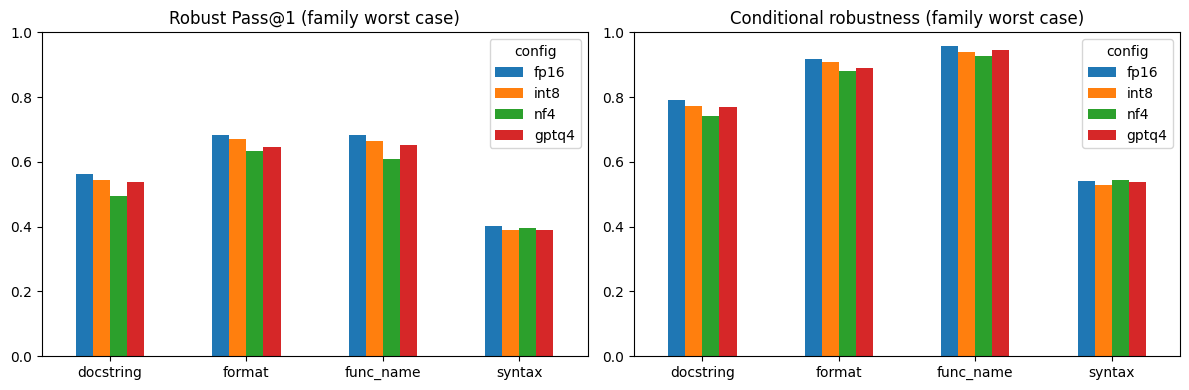

In [31]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
e1 = results[(results["eval"] == "E1") & results["variant"].str.endswith("worst_case")]
for ax, metric, title in [(axes[0], "robust_pass", "Robust Pass@1 (family worst case)"),
                          (axes[1], "conditional_robust", "Conditional robustness (family worst case)")]:
    t = e1[e1["metric"] == metric].pivot(index="variant", columns="config", values="value")[CONFIGS]
    t.index = [v.split("/")[0] for v in t.index]
    t.plot.bar(ax=ax, rot=0)
    ax.set_title(title); ax.set_ylim(0, 1); ax.set_xlabel("")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "e1_by_family.png"), dpi=150)
plt.show()

## 9. Part 6 — Report (15 pts)

Write the report in the markdown cells below. Short and specific beats long. Back every
claim with a number from `results` or `paired`.

**The confound you must handle.** A configuration that solves fewer nominal problems has
fewer problems left to break, so its *absolute* robust pass can drop less — and it can look
"more robust" for the wrong reason. Example: `fp16` solves 100 nominal problems and keeps
80 under a perturbation (20 lost); `nf4` solves 70 and keeps 60 (10 lost). Only 10 lost
looks better, yet conditional robustness is 80% for `fp16` and 86% for `nf4` — and whether
*that* gap is real is a question for Part 5. Report absolute and conditional numbers side by
side, and discuss any case where they disagree.

### 9.1 Quantization

*Library versions; for `gptq4`: calibration dataset, number of samples, sequence length, and
why you chose them. Efficiency table (size, memory, tokens/s) and what it does and does not
show (see the note on GPTQ decompression).*

I used the Colab Tesla T4 GPU runtime environment.

Library versions:
- torch 2.11.0+cu130
- transformers 5.17.0
- llmcompressor 0.14.0
- compress-tensors 0.19.0
- bitsandbytes 0.50.2

Model: Qwen/Qwen2.5-Coder-1.5B-Instruct with float16 and greedy decoding.

**GPTQ Calibration:**
- **Data:** 256 samples taken from `theblackcat102/evol-codealpaca-v1`, at most 512 tokens each. Each sample is the instructions plus the reference answer formatted with the model's chat template. I shuffled the dataset with a random seed.
- **Why this data?:** The evaluation is python code copmletion via the chat template, so code instructions with solutions match both the domain and the prompt's format.

Efficiency Table:
| Config | Weights in memory | Peak GPU memory | Tokens/s | On disk |
|---|---|---|---|---|
| fp16 | 3.09 GB | 6.38 GB | 90.1 | n/a |
| int8 | 1.78 GB | 5.41 GB | 29.4 | n/a |
| nf4 | 1.12 GB | 4.50 GB | 80.5 | n/a |
| gptq4 | 3.09 GB (dense) | 6.38 GB | 85.2 | 1.64 GB |

- nf4 gives the largest memory saving, int8 saves 42% of weight memory but is roughly 3x slower than fp16.
- gptq4 has no memory or speed benefit. It is 4-bit (only 1.64GB on disk). Its accuracy numbers are similar to those of 4-bit weights. I ran it as an ordinary fp16 model with 4-bit-valued weights, so its memory matches fp16.
- To keep it fair, peak memory is perhaps not a great metric as it is not a pure weights comparison.

### 9.2 Results

*E0 and E1 per configuration, both absolute and conditional. Which perturbation families,
if any, does quantization make worse? Do `nf4` and `gptq4` differ? Which differences
survive the paired test, and which are within noise? Then E2 (ASL and the per-loop curve)
and/or E3 (spread across templates).*

### E0

| Config | nominal | gap to fp16 | nominal_partial | gap to fp16 |
|---|---|---|---|---|
| fp16 | 0.701 | | 0.744 | |
| int8 | 0.701 | 0.0 pp | 0.738 | 0.6 pp |
| nf4 | 0.659 | 4.3 pp | 0.707 | 3.7 pp |
| gptq4 | 0.689 | 1.2 pp | 0.726 | 1.8 pp |

To check whether there is a real gap, I compared each model with fp16 problem by problem. Since two models can score the same while solving different problems, and the test looks at the problems where only one of them succeeds. The p-value is the chance of a split if the two models were truly equally good. The threshold is below 0.05.

| Config | Prompt set | Only fp16 solved | Only the config solved | p-value |
|---|---|---|---|---|
| int8 | nominal | 4 | 4 | 1.00 |
| int8 | nominal_partial | 1 | 0 | 1.00 |
| gptq4 | nominal | 8 | 6 | 0.79 |
| gptq4 | nominal_partial | 5 | 2 | 0.45 |
| nf4 | nominal | 9 | 2 | 0.065 |
| nf4 | nominal_partial | 13 | 7 | 0.26 |

int8 matches fp16. Gptq4 is a little lower, but is close enough that this could just be random chance. nf4 was roughly 4 pts lower on plain prompts, which is just short of the threshold for significance.

There were three specific results under 0.05:
- nf4 on func_name/ButterFinger (p = 0.019)
- nf4 on func_name/CamelCase (p = 0.022)
- gptq4 on syntax/VarRenamerCB (p = 0.035)

These are not significant because with 30 tests, about 1.5 would naturally fall below 0.05 by chance. This is just a hint towards behavior and not actual proof.

### E1

We can classify a problem as robust if the model passes both perturbations in it. Robust Pass@1 is the problems solved on the perturbed prompts, Conditional takes only the problems the model already solves and sees how many is still solves after perturbation, and Robust Drop@1 is the relative loss from the plain score (so 0.200 means the model lost 20% of what it could originally solve).

| Family (compared with) | Metric | fp16 | int8 | nf4 | gptq4 |
|---|---|---|---|---|---|
| docstring (nominal) | Robust Pass@1 | 0.561 | 0.543 | 0.494 | 0.537 |
| | Conditional | 0.791 | 0.774 | 0.741 | 0.770 |
| | Robust Drop@1 | 0.200 | 0.226 | 0.250 | 0.221 |
| func_name (nominal) | Robust Pass@1 | 0.683 | 0.665 | 0.610 | 0.652 |
| | Conditional | 0.957 | 0.939 | 0.926 | 0.947 |
| | Robust Drop@1 | 0.026 | 0.052 | 0.074 | 0.053 |
| syntax (nominal_partial) | Robust Pass@1 | 0.402 | 0.390 | 0.396 | 0.390 |
| | Conditional | 0.541 | 0.529 | 0.543 | 0.538 |
| | Robust Drop@1 | 0.459 | 0.471 | 0.440 | 0.462 |
| format (nominal_partial) | Robust Pass@1 | 0.683 | 0.671 | 0.634 | 0.646 |
| | Conditional | 0.918 | 0.909 | 0.879 | 0.891 |
| | Robust Drop@1 | 0.082 | 0.091 | 0.103 | 0.109 |

- Syntax seems to be the hardest family for every model including fp16.
- nf4 has slightly lower conditional robustness in three of the families, but I didn't extensively test if those gaps are "real".
- int8 and gptq4 managed to stay within 2-3 points of fp16 on everything.

nf4 scores lower than gptq4 on both of the plain sets (0.659 vs. 0.689 on the first one, 0.707 vs. 0.726 on the next) and also does worse on 5/8 of the perturbations despite doing better on the other 3. I only compared each against fp16, not against each other, so I can't conclude that the gap is real. However, the numbers would make sense if there was proof that nf4 loses more accuracy than gptq4

#### Confound:
- for nf4 on syntax, its Robust Drop is 0.440 vs. fp16's 0.459, which looks better, but its Robust Pass is actually lower (0.396 vs. 0.402) and its conditional robustness is roughly the same (0.543 vs. 0.541). The smaller drop only appears because nf4 started lower to begin with.
- for nf4 on docstring/ButterFingers, the drop looks as good as fp16's (0.074 vs. 0.078), but nf4 solves less problems (0.610 vs 0.646) and has lower conditional robustness (0.852 vs. 0.887).
- for nf4 on func_name/CamelCase, it is 0.646 vs. fp16's 0.701. This is a clean loss. Its conditional robustness is similar (0.981 vs. 0.983), and it only lost 2 of the 108 problems on plain prompts. Of the 11 problems that fp16 can solve that nf4 fails, at least 9 of them were ones that nf4 already failed on the plain prompt.

### E2

| Config | Loop 1 | Loop 2 | Loop 3 | ASL | Loop 3 as a share of loop 1 |
|---|---|---|---|---|---|
| fp16 | 115 (0.701) | 72 (0.439) | 67 (0.409) | 1.549 | 0.583 |
| int8 | 115 (0.701) | 77 (0.470) | 71 (0.433) | 1.604 | 0.617 |
| nf4 | 108 (0.659) | 72 (0.439) | 69 (0.421) | 1.518 | 0.639 |
| gptq4 | 113 (0.689) | 72 (0.439) | 67 (0.409) | 1.537 | 0.593 |

This is EvaLoop. It is supposed to be a robustness test that sees how long a model can iterate on just its own description of its solution (how long can it survive?).
- Loop 1 did the same as the plain-prompt score. The first real iteration/round loses between 30-40% for every configuration.
- ASL ranges roughly from 1.52 to 1.60. At loop 3, the configs differ by at most 4/164 of the problems. I did not extensively test these small differences.
- We get the same "confound" here where nf4 looks best in the last column because it started lower than all the others. Its actual loop 3 count is about the same as fp16's (69 vs. 67).

Greedy decoding is deterministic, so it makes sense that the survivors stop changing after about 2 loops. ASL can't really separate configs that differ by just a few problems.

### 9.3 Three flipped examples

*At least three problems that the `fp16` model solves under a perturbation and a quantized
model does not (or the reverse). For each: the perturbation, both completions (find them in
`SAMPLES`), and your explanation of what went wrong.*

These are specific examples from `func_name/CamelCase`, which is function names changed from snake_case to camelCase, that fp16 solved and nf4 did not. This is taken from the output of `flips("func_name/CamelCase")`.

1. HumanEval/98, `countUpper from count_upper`
- fp16 passes and loops with `range(0, len(s), 2)` (even positions).
- nf4 fails and loops with `range(1, len(s), 2)`, which counts the odd positions. The docstring says even positions.
- nf4 failed because of an off-by-one where the loop starts, which was a small slip up in reading the task.
2. HumanEval/65, `circularShift from circular_shift`
- fp16 passes using `num_str[-shift:] + num_str[:-shift]` which is a right rotation, as the task asked for.
- nf4 fails because it uses `str(x)[shift:] + str(x)[:shift]` which is a left rotation.
- nf4 failed because it used the wrong direction. The docstring example wouldn't have caught it since a two-digit number gets the same answer on either a right or left rotation.
3. HumanEval/19, `sortNumbers from sort_numbers`
- fp16 passes using `key=lambda word: number_map[word]`.
- nf4 fails with `KeyError: 3`. It turns the words into numbers, sorts the numbers, then tries to turn them back using `number_map[value]` but `number_map` is mapped from words to numbers and not the other way around, so trying to look up a number will fail.
- nf4 failed because of a mistake in a two-step conversion, which is a logic error.
4. HumanEval/57, `monotonic` -> this is a control case
- fp16 passes with one loop that tracks whether the list is rising or falling.
- nf4 fails because it uses strict instead of non-strict copmarisons, which causes a list with equal neighbors to fail.
- monotonic is a control case because it is already in camel case.

All four of these mistakes have one thing in common: nf4 understood the overall task, but got a small detail regarding the task incorrect, which caused it to perform the wrong changes and get the wrong answer.

In [32]:
# helper: find flips for one perturbation and show both completions
def flips(dataset, a="fp16", b="nf4", limit=5):
    pa, pb = PASS[a][dataset], PASS[b][dataset]
    ids = [t for t in pa if pa[t] and not pb[t]][:limit]
    for t in ids:
        for config in (a, b):
            s = next(s for s in SAMPLES if s["config"] == config and s["variant"] == dataset and s["item_id"] == t)
            print(f"===== {t} [{config}] {s['status']}")
            print(s["prompt"] + s["output"])
    return ids

flips("func_name/CamelCase")

===== HumanEval/19 [fp16] passed
from typing import List


def sortNumbers(numbers: str) -> str:
    """ Input is a space-delimited string of numberals from 'zero' to 'nine'.
    Valid choices are 'zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight' and 'nine'.
    Return the string with numbers sorted from smallest to largest
    >>> sortNumbers('three one five')
    'one three five'
    """
    # Define a dictionary to map number words to their numeric values
    number_map = {
        'zero': 0, 'one': 1, 'two': 2, 'three': 3, 'four': 4,
        'five': 5, 'six': 6, 'seven': 7, 'eight': 8, 'nine': 9
    }
    
    # Split the input string into a list of number words
    number_words = numbers.split()
    
    # Sort the list of number words based on their numeric values
    sorted_number_words = sorted(number_words, key=lambda word: number_map[word])
    
    # Join the sorted list of number words back into a string
    sorted_numbers = ' '.join(sorted_number_words

['HumanEval/19',
 'HumanEval/20',
 'HumanEval/57',
 'HumanEval/65',
 'HumanEval/98']

### 9.4 Conclusion and threats to validity

*Your answer to the assignment's question, at the confidence your data supports. What could
make it wrong: one model, one seed per transformation, greedy decoding, the subset of
perturbations, the calibration set, decompressed GPTQ inference, and anything else you noticed.*

I found no evidence that any of the three quantization methods make the models more fragile than its clean score already shows.
- int8 scored the same as fp16 on both plain and perturbed prompts.
- nf4 loses about 4 points on plain and perturbed prompts both. The perturbed loss is about the same size, so it's mostly the same loss of accuracy that we expect from quantization regardless of the prompt.
- gptq4 has a small loss of about 1-2 points and two perturbations specifically were a bit worse than the clean gap, but this is hardly enough to support a claim.

nf4 and gptq4 may carry a small extra loss that I didn't perform enough testing to properly make claims on, but these results are consistent with Wei et al, whose abstract describes that quantization had no significant accuracy or robustness loss.

### What could make this wrong:
- A 1.5B model may react differently to quantization than larger ones
- Lack of statistical significance/small sample size of 164 problems. With such small sample size, a difference of 2-3 points is practically undetectable.
- I did not test conditional robustness, which is a key quantity to analyze the "confound" that is mentioned in this assignment.
- Greedy decoding is fixed and repeatable, but it hides the variation from run to run.
- I used only 8 of ReCode's transformations (2 per family), so it is unknown to me whether other types of perturbations might have actually changed the results at the family level.
- gptq4 ran as an fp16 model with 4-bit-valued weights because the library's loader had random initialization of the quantized layers.
- Using one seed per perturbation might not give us the whole picture.
- Using this calibration set (just one set) and one seed makes it difficult to generalize our conclusion outside of this set. Maybe gptq4 would do better on a different set?
- Using three loops under greedy decoding for E2 (EvaLoop) saturates really quickly.
- Finally, the base model may have actually seen HumanEval during training. This would inflate every config (but we can't really get around this).

### 9.5 AI assistance

*What you used and for what.*

I used Claude.ai to help understand the code we were given and to help explain to me what the purpose and task for me in this assignment was. I used it along the way to guide me in my interpretations of results if I got confused, and also had it aid in my implementations when they ran into errors. At a high level, I used it to make sure I wasn't going rogue and misunderstanding the task at hand, as well as speeding up the process of making changes to code.

## 10. Part 7 — Submit

Run the check below. It only checks that the run is complete, not that it is correct.

Then upload **two files** to Gradescope:

1. **This notebook, with all its outputs.** Run it top to bottom with `QUICK = False`, then
   *File → Download → Download .ipynb*. A notebook without outputs cannot be graded.
2. **`README.md`** explaining your code. Keep it short — a few lines per item:
   - how to run the notebook, and the library versions you used (Part 0 prints them);
   - for each TODO: what your implementation does and any choice you made — in particular
     the GPTQ calibration dataset, number of samples and sequence length, and why;
   - every place you departed from a paper's protocol (ReCode, EVALOOOP, Sclar et al.), and why;
   - which of E2 / E3 you ran;
   - any material AI assistance.

The report itself (results, flipped examples, conclusion) stays in Part 6 of the notebook.

In [33]:
def check_complete():
    df = pd.DataFrame(RESULTS)
    problems = []
    if QUICK:
        problems.append("QUICK is still True: the graded run must use all 164 problems")
    for config in CONFIG_META:
        if not ((df["config"] == config) & (df["eval"] == "E0")).any():
            problems.append(f"no E0 result for {config}")
        for family in RECODE_SUBSET:
            if not ((df["config"] == config) & (df["variant"] == f"{family}/worst_case")).any():
                problems.append(f"no E1 {family} result for {config}")
    if not (df["eval"].isin(["E2", "E3"])).any():
        problems.append("neither E2 nor E3 was run")
    if df["value"].isna().any():
        problems.append("some result values are missing")
    print("\n".join(problems) or "run complete - download the notebook and write your README")
    return not problems


check_complete()

run complete - download the notebook and write your README


True